# Student 2 · Traffic Predictor — A. Get and check the data

**Smart Intersection Brain (CS4085)**

1. Install PyTorch Geometric Temporal and load **METR-LA** (207 road sensors on Los Angeles highways, one speed reading every 5 minutes, Mar–Jun 2012).
2. Count how many readings are **zero**. In METR-LA a zero means *the sensor sent nothing* (missing), **not** stopped traffic.

Runs on Google Colab (CPU is enough) or locally.

## 1. Install

In [1]:
import sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # torch is already installed on Colab
    !pip -q install torch-geometric h5py
    # --no-deps: the package pins torch_sparse/torch_scatter, which need a slow C++ build.
    # The dataset loader and the GCN/GRU layers we use do not need them.
    !pip -q install --no-deps torch-geometric-temporal

In [2]:
import types
# torch_geometric_temporal imports torch_sparse at package level (only EvolveGCN uses it).
# If it is not installed, register an empty stand-in so the package can be imported.
try:
    import torch_sparse  # noqa: F401
except ImportError:
    _stub = types.ModuleType("torch_sparse")
    _stub.SparseTensor = object
    sys.modules["torch_sparse"] = _stub

import os, urllib.request
import numpy as np, pandas as pd, h5py, torch
import matplotlib.pyplot as plt
from torch_geometric_temporal.dataset import METRLADatasetLoader
print("torch", torch.__version__)

/home/user/SIREN/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/user/SIREN/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


torch 2.15.0+cu132


## 2. Download and load METR-LA

`METRLADatasetLoader` downloads `METR-LA.zip` (from Box) into the data folder and loads it.
If Box is unreachable, we fetch the same zip from a GitHub mirror (the original STGCN-PyTorch repo, where this zip comes from).

We also download the original DCRNN file `metr-la.h5`, which carries the **timestamps** and **sensor IDs** (the zip has neither).

In [3]:
# Repo root = parent of forecaster/ when run from the repo; the current folder on Colab
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "forecaster" else os.getcwd()
DATA_DIR = os.path.join(ROOT, "data", "raw")   # absolute path: the loader breaks on relative paths
os.makedirs(DATA_DIR, exist_ok=True)

MIRRORS = {
    # PyG Temporal zip: adj_mat.npy + node_values.npy
    "METR-LA.zip": "https://raw.githubusercontent.com/FelixOpolka/STGCN-PyTorch/master/data/METR-LA.zip",
    # Original DCRNN data: speeds with timestamps + sensor ids (Git LFS file)
    "metr-la.h5": "https://media.githubusercontent.com/media/kevinkbc/DCRNN_PyTorch/master/data/metr-la.h5",
    # Sensor graph + GPS locations from the official DCRNN repo (used later by the map)
    "adj_mx.pkl": "https://raw.githubusercontent.com/liyaguang/DCRNN/master/data/sensor_graph/adj_mx.pkl",
    "graph_sensor_locations.csv": "https://raw.githubusercontent.com/liyaguang/DCRNN/master/data/sensor_graph/graph_sensor_locations.csv",
}

try:
    loader = METRLADatasetLoader(raw_data_dir=DATA_DIR)          # official route (Box)
except Exception as e:
    print("Loader download failed:", type(e).__name__, "-> using GitHub mirror")
    urllib.request.urlretrieve(MIRRORS["METR-LA.zip"], os.path.join(DATA_DIR, "METR-LA.zip"))
    loader = METRLADatasetLoader(raw_data_dir=DATA_DIR)

for name, url in MIRRORS.items():
    path = os.path.join(DATA_DIR, name)
    if not os.path.isfile(path):
        urllib.request.urlretrieve(url, path)
    print(f"{name:28s} {os.path.getsize(path)/1e6:7.2f} MB")

METR-LA.zip                    15.72 MB
metr-la.h5                     57.04 MB
adj_mx.pkl                      0.68 MB
graph_sensor_locations.csv      0.01 MB


In [4]:
print("Loader X (nodes, features, time):", tuple(loader.X.shape))
print("Loader A (adjacency):            ", tuple(loader.A.shape))
print("Edges with weight > 0:", int((loader.A > 0).sum()))

Loader X (nodes, features, time): (207, 2, 34272)
Loader A (adjacency):             (207, 207)
Edges with weight > 0: 1722


The loader returns **z-scored** values (2 features: speed, time-of-day), so a zero reading no longer shows as 0.
To count zeros we use the **raw** speeds in mph: `node_values.npy` (same numbers) or `metr-la.h5` (with timestamps).

In [5]:
with h5py.File(os.path.join(DATA_DIR, "metr-la.h5"), "r") as f:   # old pandas/py2 file: read it with h5py
    sensor_ids = f["df/axis0"][:].astype(str)
    times      = pd.to_datetime(f["df/axis1"][:])
    speed_np   = f["df/block0_values"][:]

speed = pd.DataFrame(speed_np, index=times, columns=sensor_ids)   # (time, sensor), mph

raw = np.load(os.path.join(DATA_DIR, "node_values.npy"))          # (time, sensor, 2)
assert np.allclose(raw[..., 0], speed.values), "h5 and zip disagree"
assert (np.diff(times.values) == np.timedelta64(5, "m")).all(), "time grid has gaps"

print(f"Shape: {speed.shape[0]:,} time steps x {speed.shape[1]} sensors = {speed.size:,} readings")
print(f"From {times[0]} to {times[-1]}, every 5 min (no gaps in the time grid)")
print(f"Speed range: {speed.values.min():.1f} to {speed.values.max():.1f} mph")
speed.iloc[:6, :6]

Shape: 34,272 time steps x 207 sensors = 7,094,304 readings
From 2012-03-01 00:00:00 to 2012-06-27 23:55:00, every 5 min (no gaps in the time grid)
Speed range: 0.0 to 70.0 mph


,773869,767541,767542,717447,717446,717445
2012-03-01 00:00:00,64.375000,67.625000,67.125000,61.500000,66.875000,68.750000
2012-03-01 00:05:00,62.666667,68.555556,65.444444,62.444444,64.444444,68.111111
2012-03-01 00:10:00,64.000000,63.750000,60.000000,59.000000,66.500000,66.250000
2012-03-01 00:15:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2012-03-01 00:20:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2012-03-01 00:25:00,57.333333,69.000000,67.666667,61.666667,67.333333,69.000000


## 3. Count the zeros (= missing readings)

In [6]:
missing = (speed == 0)                      # True where the sensor sent nothing
n_zero, n_all = int(missing.values.sum()), missing.size
print(f"Zero readings: {n_zero:,} of {n_all:,}  ->  {n_zero/n_all:.2%} missing")

per_sensor = missing.mean().sort_values(ascending=False)
per_step   = missing.sum(axis=1)
print(f"Sensors with no zeros at all : {(per_sensor == 0).sum()}")
print(f"Sensors with  >10% zeros     : {(per_sensor > 0.10).sum()}")
print(f"Sensors with  >50% zeros     : {(per_sensor > 0.50).sum()}")
print(f"Time steps where ALL 207 sensors are zero: {(per_step == speed.shape[1]).sum():,} "
      f"({(per_step == speed.shape[1]).mean():.2%} of time steps)")
print(f"Time steps with at least one zero:         {(per_step > 0).sum():,}")
from_outages = missing[per_step == speed.shape[1]].values.sum()
print(f"Zeros that come from those network-wide outages: {from_outages:,} ({from_outages/n_zero:.0%} of all zeros)")
print("\nWorst 10 sensors (share of readings missing):")
print(per_sensor.head(10).map("{:.1%}".format).to_string())

Zero readings: 575,302 of 7,094,304  ->  8.11% missing
Sensors with no zeros at all : 0
Sensors with  >10% zeros     : 34
Sensors with  >50% zeros     : 0
Time steps where ALL 207 sensors are zero: 2,148 (6.27% of time steps)
Time steps with at least one zero:         29,066
Zeros that come from those network-wide outages: 444,636 (77% of all zeros)

Worst 10 sensors (share of readings missing):
718076    20.1%
716939    18.9%
760987    16.1%
716955    15.7%
769418    15.6%
769405    15.6%
717481    15.1%
717510    15.0%
717513    14.1%
717576    13.6%


### Why zero means *missing*, not *stopped traffic*

If zeros were real jams we would expect speeds to slide smoothly down to 0. Instead there is a jump:
almost no readings between 0 and a few mph, and zeros often hit **all sensors at the same moment** (a data-collection outage).

In [7]:
v = speed.values
nonzero = v[v > 0]
print(f"Readings exactly 0         : {n_zero:,}")
print(f"Readings in (0, 5) mph     : {((v > 0) & (v < 5)).sum():,}")
print(f"Readings in [5, 10) mph    : {((v >= 5) & (v < 10)).sum():,}")
print(f"Smallest non-zero speed    : {nonzero.min():.2f} mph")

# Length of each run of consecutive zeros, per sensor
runs = []
for col in missing.columns:
    m = missing[col].values.astype(np.int8)
    edges = np.flatnonzero(np.diff(np.r_[0, m, 0]))
    runs.extend(edges[1::2] - edges[::2])
runs = np.array(runs)
print(f"\nRuns of consecutive zeros: {len(runs):,}; median {np.median(runs):.0f} steps "
      f"({np.median(runs)*5:.0f} min), longest {runs.max():,} steps ({runs.max()*5/60/24:.1f} days)")

Readings exactly 0         : 575,302
Readings in (0, 5) mph     : 3,378
Readings in [5, 10) mph    : 26,431
Smallest non-zero speed    : 0.33 mph

Runs of consecutive zeros: 25,963; median 2 steps (10 min), longest 1,683 steps (5.8 days)


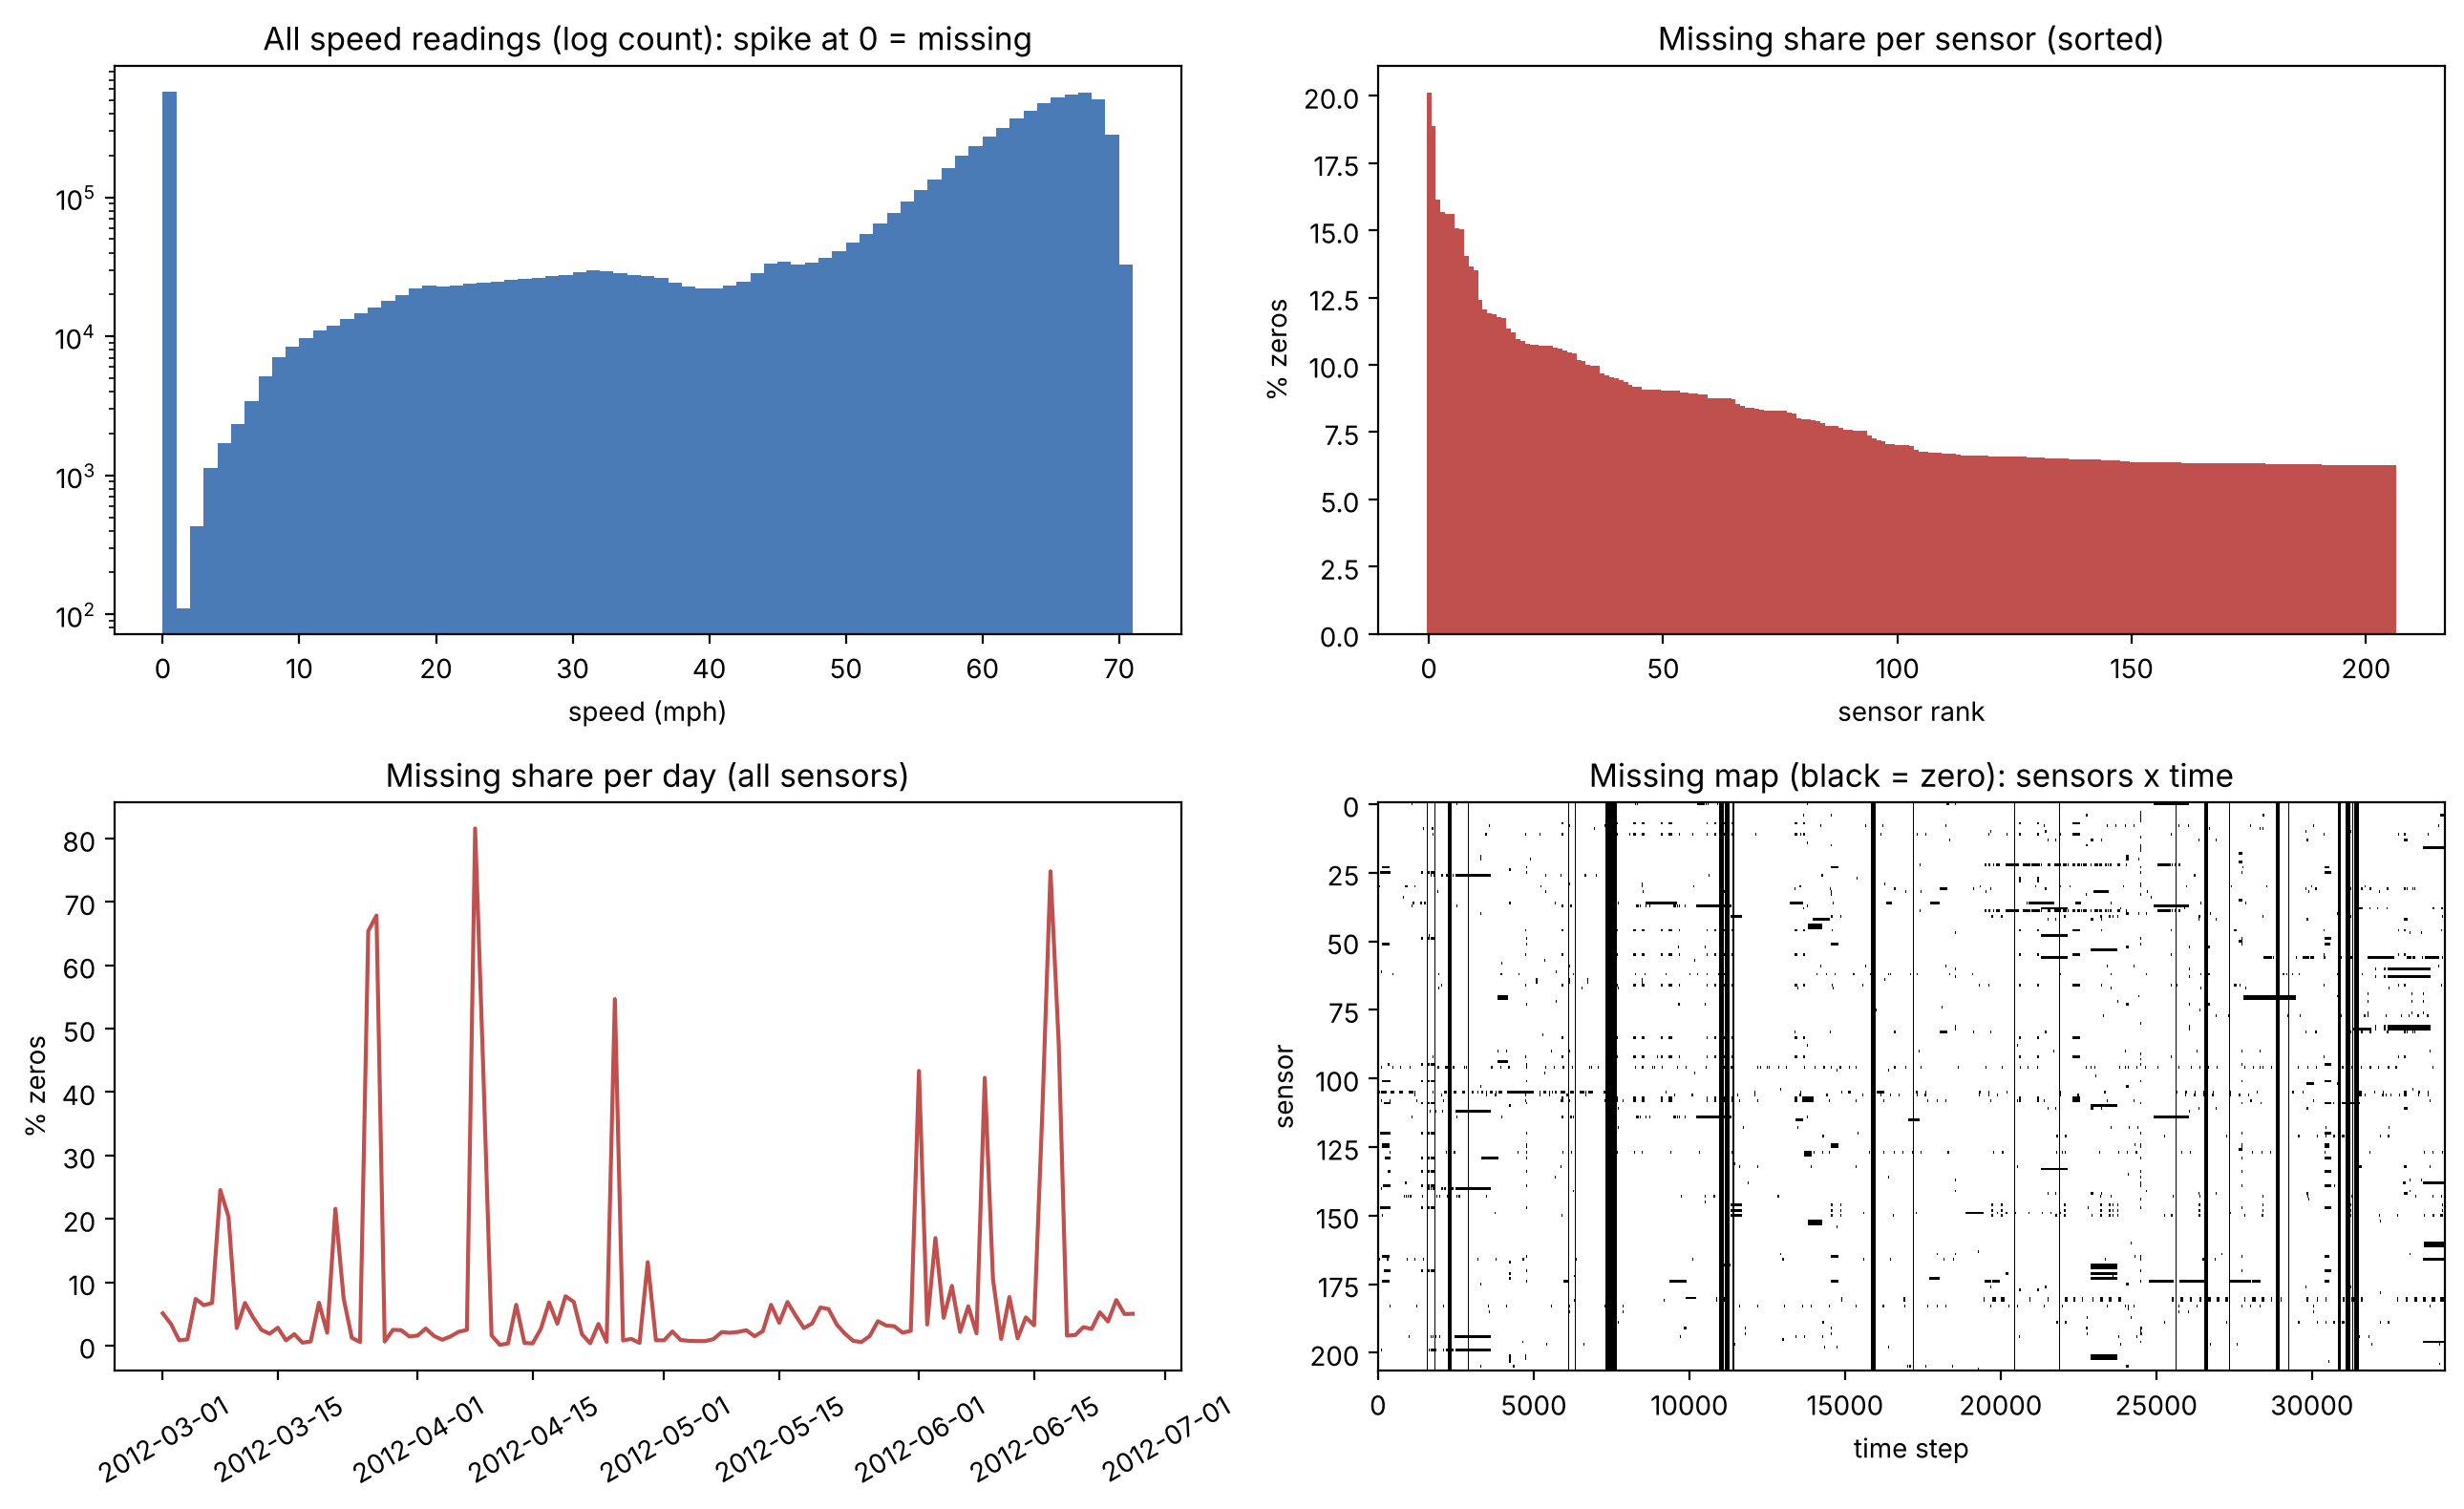

In [8]:
fig, ax = plt.subplots(2, 2, figsize=(13, 8))

ax[0, 0].hist(v.ravel(), bins=71, range=(0, 71), color="#4a7bb7")
ax[0, 0].set_yscale("log"); ax[0, 0].set_title("All speed readings (log count): spike at 0 = missing")
ax[0, 0].set_xlabel("speed (mph)")

ax[0, 1].bar(range(len(per_sensor)), per_sensor.values * 100, color="#c0504d", width=1)
ax[0, 1].set_title("Missing share per sensor (sorted)"); ax[0, 1].set_ylabel("% zeros")
ax[0, 1].set_xlabel("sensor rank")

daily = missing.mean(axis=1).resample("D").mean() * 100
ax[1, 0].plot(daily.index, daily.values, color="#c0504d")
ax[1, 0].set_title("Missing share per day (all sensors)"); ax[1, 0].set_ylabel("% zeros")
ax[1, 0].tick_params(axis="x", labelrotation=30)

ax[1, 1].imshow(missing.values.T, aspect="auto", interpolation="nearest", cmap="Greys")
ax[1, 1].set_title("Missing map (black = zero): sensors x time")
ax[1, 1].set_xlabel("time step"); ax[1, 1].set_ylabel("sensor")
plt.tight_layout()
os.makedirs(os.path.join(ROOT, "figures"), exist_ok=True)
plt.savefig(os.path.join(ROOT, "figures", "metr_la_missing.png"), dpi=120)
plt.show()

### What the zeros do to the PyG loader's output

The loader z-scores with the zeros **included**, so every missing reading becomes the same constant `-mean/std`
and the mean itself is pulled down. A model trained on that would learn to predict fake "0 mph" drops.

In [9]:
spd = raw[..., 0].astype(np.float32)
mean_all, std_all = spd.mean(), spd.std()
mean_ok,  std_ok  = spd[spd > 0].mean(), spd[spd > 0].std()
print(f"Mean / std with zeros   : {mean_all:.2f} / {std_all:.2f} mph   (what the loader uses)")
print(f"Mean / std without zeros: {mean_ok:.2f} / {std_ok:.2f} mph")
z0 = (0 - mean_all) / std_all
x_at_missing = loader.X[:, 0, :].numpy().T[missing.values]      # loader values where raw speed is 0
print(f"Expected value of a missing reading in loader.X: {z0:.3f}")
print(f"Actual values there: min {x_at_missing.min():.3f}, max {x_at_missing.max():.3f} "
      f"({len(x_at_missing):,} readings, all the same constant)")

Mean / std with zeros   : 53.72 / 20.26 mph   (what the loader uses)
Mean / std without zeros: 58.46 / 13.02 mph
Expected value of a missing reading in loader.X: -2.651
Actual values there: min -2.652, max -2.652 (575,302 readings, all the same constant)


## 4. Takeaways for the next steps

- **8.1%** of METR-LA readings (575,302 of 7.09 M) are 0 = missing. About three quarters of them come from network-wide outages where all 207 sensors are 0 at once; the rest are single sensors dropping out (worst sensor: 20% missing). Every sensor has some zeros.
- **Do not** feed zeros as real speeds. Follow DCRNN: keep zeros in the inputs if needed, but use a **masked MAE / RMSE** that ignores targets equal to 0, so the scores match the paper.
- Compute normalisation mean/std **on the training split only** and **without zeros**.
- Use the DCRNN split: first 70% train, next 10% validation, last 20% test (in time order).
- For the app: avoid placing the ambulance at a sensor with many missing readings.

In [10]:
# Save the mask and per-sensor missing table for later notebooks / the app
OUT = os.path.join(ROOT, "data", "processed"); os.makedirs(OUT, exist_ok=True)
np.save(os.path.join(OUT, "metr_la_missing_mask.npy"), missing.values)
per_sensor.rename("missing_share").to_csv(os.path.join(OUT, "metr_la_missing_per_sensor.csv"), header=True)
print("saved data/processed/metr_la_missing_mask.npy and metr_la_missing_per_sensor.csv")

saved data/processed/metr_la_missing_mask.npy and metr_la_missing_per_sensor.csv
